<p><b>230266B - Jathunwaththa J.C.R.N.</b></p>

In [72]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

<h2><b>Question 01</b></h2>

Image dimensions: (360, 360)


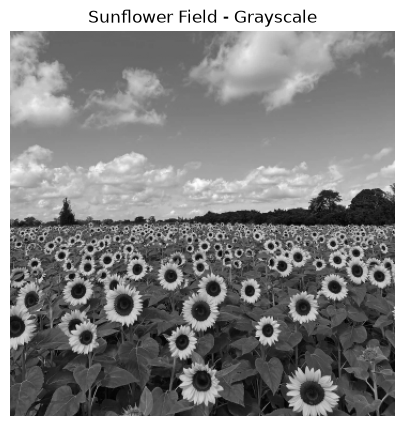

In [14]:
im = cv.imread(
    './a2images/the_berry_farms_sunflower_field.jpeg',
    cv.IMREAD_REDUCED_COLOR_4
)

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
print("Image dimensions:", gray.shape)

plt.figure(figsize=(8, 5))
plt.imshow(gray, cmap="gray")
plt.title("Sunflower Field - Grayscale")
plt.axis("off")
plt.show()

In [ ]:
def scaled_log_kernel(sigma):
    radius = int(np.ceil(3 * sigma))
    coords = np.arange(-radius, radius + 1)

    x, y = np.meshgrid(coords, coords)
    r2 = x**2 + y**2

    kernel = (r2 - 2 * sigma**2) / (2 * np.pi * sigma**4) * np.exp(-r2 / (2 * sigma**2))
    kernel -= kernel.mean()
    
    return kernel.astype(np.float32)


def find_scale_space_maxima(scale_space, sigmas, threshold):
    neighborhood = np.ones((3, 3, 3), dtype=np.uint8)
    local_max = maximum_filter(scale_space, size=(3, 3, 3), mode="nearest")
    is_max = ((scale_space == local_max) & (scale_space > threshold))

    is_max[0, :, :] = False
    is_max[-1, :, :] = False

    ks, ys, xs = np.where(is_max)
    candidates = [(x, y, sigmas[k], scale_space[k, y, x]) for k, y, x in zip(ks, ys, xs)]

    return candidates




In [ ]:
sigmas = np.arange(0.5, 10, 0.5)
gray_float = gray.astype(np.float32) / 255.0
responses = []

for sigma in sigmas:
    kernel = scaled_log_kernel(sigma)
    response = cv.filter2D(
        gray_float,
        cv.CV_32F,
        kernel,
        borderType=cv.BORDER_REFLECT
    )
    responses.append(np.abs(response))

scale_space = np.stack(responses, axis=0)
candidates = find_scale_space_maxima(scale_space, sigmas, threshold=0.29)
print("Number of candidate blobs:", len(candidates))

Number of candidate blobs: 66


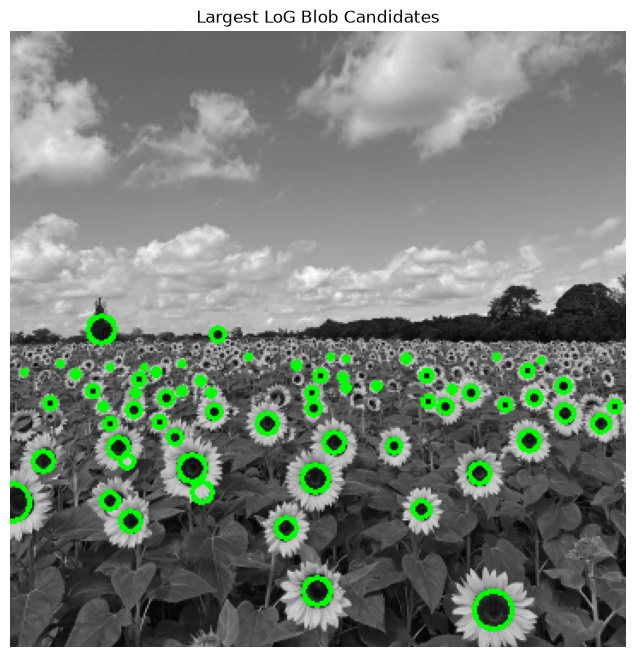

Largest circle: center=(282, 338), radius=11, response=0.35212352871894836


In [77]:
result = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)

# Sort by estimated radius, largest first
candidates.sort(key=lambda c: c[2], reverse=True)

for x, y, sigma, response in candidates:
    radius = int(round(np.sqrt(2) * sigma))
    cv.circle(result, (x, y), radius, (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Largest LoG Blob Candidates")
plt.axis("off")
plt.show()

# Parameters of the largest circle
if candidates:
    x, y, sigma, response = candidates[1]
    radius = int(round(np.sqrt(2) * sigma))
    print(f"Largest circle: center=({x}, {y}), radius={radius}, response={response}")


<h2><b>Question 02</b></h2>